# Task 1: Implementing SGA

## Introduction

This task covers the implementation of a Simple Genetic Algorithm (SGA) from the ground up. The algorithm, in its simplest form, can described as follows.

```pseudocode
Initialize population P of size N.
For G Generations: 
    Evaluate fitness of each individual in P
    Selects parents from P
    Apply one-point crossover on parents to create offspring
    Apply mutation on each offspring created
    Evaluate fitness of offspring
    Select the best individuals from current population and offspring
    Form new population P from the selected survivors
Return fitness history and population
```

Both the contents of this report and the algorithm are divided by the individual functions implemented to perform key functionalities of the SGA. Each function is accompanied with a **subtask**, where the function is tested with some specified input, and its results are discussed.

### Input Space

Individuals of a population are analogs of a genetic representation, and fall into two categories: 

- **Phenotype:** Integer values
- **Genotype:** 6-bit binary strings.

Integer values are encoded as 6-bit binary strings (represented as a list) e.g., [0, 1, 0, 0, 0, 1] is 17. With 6 bits for each string, the values range from a minimum 0 to a maximum of 63. 

Populations are then represented by a list of list, e.g., [[0, 1, 0, 0, 0, 1], [1, 0, 0, 1, 1, 0], [0, 0, 1, 0, 0, 1]] is equivalent to [17, 38, 9].

## Starting Point

To ensure reproducability for multiple, different runs of the algorithm, we use a fixed seed that the `random` and `np.random` modules pull from. 
- **Seed:** 22040 (last five digits of the smallest student number in the group)    

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

SEED = 22040 # Fixed number for the RNG to ensure reproducability.
random.seed(SEED)
np.random.seed(SEED)


## Implementation

Below is the implementation of inidvidual functions- and the algorithm in its entirity. 

### Individual Functions

#### **Conversion Functions**

Used to convert the input space from **Genotype** to **Phenotype** and vice-versa, 

In [2]:
def geno_to_pheno(individuals):
    """Returns a list of the integer values corresponding to their the 6-bit binary value."""
    return [int("".join(map(str, individual)), 2) for individual in individuals]

def pheno_to_geno(x_values):
    """Returns a 6-bit binary string encoded as a list of integers."""
    return [[int(bit) for bit in format(x_value, '06b')] for x_value in x_values]

##### **Helper Function**

This small function is used to provide a clean, readable output formatting for the **Genotype** (binary string).

In [3]:
def geno_to_str( geno: list[list[int]] ):
    return "".join(map(str, geno))

#### **1. Initialization Function: (Inputs: Population Size; Output: Individuals)** 

This function creates individuals for a population of size `pop_size`, each having 6-bit genes chosen by random. It returns the individuals as a list of lists e.g., [[0, 1, 1, 0, 1,0], [0, 1, 1, 1, 1,1]].

In [4]:
def initialization_population( pop_size: int, num_bits: int=6  ) -> list[list[int]]:
    """This function creates individuals for a population of size pop_size, each having 6-bit genes chosen by random. 
    It returns the individuals as a list of lists e.g., [[0, 1, 1, 0, 1,0], [0, 1, 1, 1, 1,1]]. """
    population = []
    for _ in range(pop_size):
        population.append(np.random.randint(0, 2, num_bits, int).tolist()) # individual (6-bit binary string)
    return population

##### **Initalization Subtask** 

Tests the `initialization_population` function by having it generates 4 individuals. It outputs each one in order, and their type.

In [5]:
def initialize_population_subtask():
    individuals_geno = initialization_population(4)

    print("\033[1mIndividuals Generated (Genotype)\033[0m")
    print("-" * 36)
    for num, individual in enumerate(individuals_geno):
        print(f"Individual {num + 1}: {geno_to_str(individual)}, {type(individual)}")

    print("-" * 36)
    print(f"Population Type: {type(individuals_geno)}")

initialize_population_subtask()

Individuals Generated (Genotype)
------------------------------------
Individual 1: 100100, <class 'list'>
Individual 2: 101001, <class 'list'>
Individual 3: 111111, <class 'list'>
Individual 4: 111000, <class 'list'>
------------------------------------
Population Type: <class 'list'>


#### **2. Fitness Function: (Inputs: Individuals; Output: Fitness values)**

This function takes a list of individuals as input, converts them to their integer value, and evaluates each individuals fitness value. It returns list of fitness values.  

The fitness evaluation equation is given as follows.

$$
y =
\begin{cases}
    x − 64, & \text{ if } x \ge 32 \\
    x, & \text{ if } x < 32
\end{cases}
\\
$$

$$
\begin{aligned}
    \text{fitness} &= − 0.00008333y^6 − 0.001y^5 + 0.09375y^4 \\
                   & \quad + 1.16667y^3 − 19.53125y^2 − 234.375y + 8350
\end{aligned}
$$

In [6]:
def fitness( individuals: list[list[int]] ) -> list[float]:
    """This function takes a list of individuals as input, converts them to their integer value, 
    and evaluates each individuals fitness value. Returns list of fitness values. """
    coeffs_exps_pairs = [
        (-0.00008333, 6),
        (-0.001, 5),
        (0.09375, 4),
        (1.16667, 3),
        (-19.53125, 2),
        (-234.375, 1),
        (8350, 0)
    ]

    def evaluate( value: float ) -> float:
        y_val = value - 64 if value >= 32 else value
        return sum(
                coeff * y_val**exp
                for coeff, exp in coeffs_exps_pairs
        )

    return [evaluate(value) for value in geno_to_pheno(individuals)]

##### **Fitness Subtask**

This subtask is compromised of two objectives:

1. Check for the individual = 010101 that their fitness value is approximately $\mathbf{12620.97}$. 
2. Plot the fitness landscape (x-axis: integer values; y-axis: fitness) for all possible integer values.

Individual (Geno)  | Expected Fitness | Actual Fitness 
-------------------|------------------|---------------
010101             | 12_620.97        | 12_620.976507

- Fitness value IS within range: [12_620,12_621]

Plotting distribution of fitness values for all possible phenotype values (0 - 63):


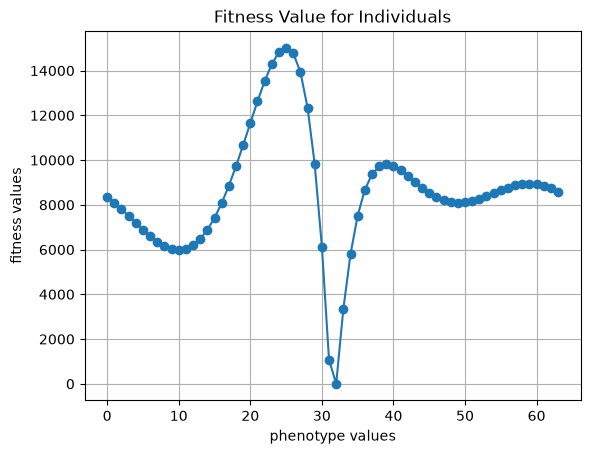

x-values corresponding to minimum/maximum fitness:

x-value | Fitness Value
--------|--------------
32      | 4.0832461
25      | 15024.0429688


In [7]:
def fitness_subtask( individual: list[list[int]], samples: int ):
    expected = 12_620.97
    fitness_value = fitness(individual)

    print(f"\033[1mIndividual (Geno)\033[0m{"":<1} | \033[1mExpected Fitness\033[0m | \033[1mActual Fitness\033[0m ")
    print("-" * 19 + "|" + "-" * 18 + "|" + "-" * 15)
    print(f"{geno_to_str(individual[0])}{"":<12} | {expected:_} {"":<6} | {fitness_value[0]:_.6f}\n")

    if 12_620 <= fitness_value[0] <= 12_621:
        print(f"- Fitness value IS within range: [{12_620:_},{12_621:_}]\n")
    else:
        print(f"- Fitness value NOT within range: [{12_620:_},{12_621:_}]\n")

    print("Plotting distribution of fitness values for all possible phenotype values (0 - 63):")
    x_vals = list(range(samples))
    fitness_values = fitness(pheno_to_geno(x_vals))

    x_min = np.argmin(fitness_values)
    x_max = np.argmax(fitness_values)

    plt.plot(x_vals, fitness_values, marker='o')
    plt.title("Fitness Value for Individuals")
    plt.xlabel("phenotype values")
    plt.ylabel("fitness values")
    plt.grid(True)
    plt.show()

    print("x-values corresponding to minimum/maximum fitness:\n")
    print("\033[1mx-value\033[0m | \033[1mFitness Value\033[0m")
    print("-" * 8 + "|" + "-" * 14)    
    print(f"{x_min:<7} | {fitness_values[x_min]:.7f}")
    print(f"{x_max:<7} | {fitness_values[x_max]:.7f}")

fitness_subtask([[0, 1, 0, 1, 0, 1]], 64)

The x-values that correspond to the global minimum- and maximum fitness:

|             | **Minimum** | **Maximum**   |
|-------------|-------------|---------------|
| **x-value** | 32          | 25            |
| **fitness** | 4.083       | 15024.043     |

With all positive fitness values, the parent selection function can safely assign fitness-proportional probabilities for its selection criteria without having to shift or scale the values to accomodate it.

##### **Generate Trial Set**

This function is useful for later subtasks as it quickly generates, and returns a uniform population of size `samples`, their fitness values, and the x-values that correspond to the minimum and maximum fitness across that range.

In [8]:

def generate_population_and_fitness_values( samples: int=64 ) -> tuple[list[int], list[float], float, float]:
    """Helper function to generate N samples and their fitness values. 
    Returns the individuals, their fitness values, and the x-values that correspond to the min/max fitness."""
    x_values = list(range(samples))
    fitness_values = fitness(pheno_to_geno(x_values))
    x_min = np.argmin(fitness_values)
    x_max = np.argmax(fitness_values)
    return x_values, fitness_values, x_min, x_max


##### **3. Parent Selection Function: (Inputs: Individuals, Fitness values; Output: Parents (in random order))**

Perform fitness-proportional selection such that more fit parents have a higher probability to be selected.Returns a list of the selected individuals in random order.

In [9]:
def parent_selection( individuals: list[list[int]], fitness_values: list[float] ) -> list[list[int]]:
    """Perform fitness-proportional selection such that more fit parents have a higher probability to be selected. 
    Returns a list of the selected individuals in random order """
    fitness = np.array(fitness_values, dtype=float)
    probs = fitness / fitness.sum()
    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]

##### **Parent Selection Subtask**

This subtask tests the `parent_selection` function by providing it a set of four individuals to perform on. The individuals chosen are those who correspond to: 

1. minimum fitness, 
2. moderate fitness,
3. moderate fitness,
4. and maximum fitness.
    
These individuals were deliberately chosen to test the fitness-proportional selection criteria, that is, we expect that the individual with the highest fitness value is selected the most and we want to verify that. 

This subtask performs two distinct generation-demos: 

- **First demo** performs a "single-iteration" of the selection process, but due to the selection being influenced by a randomized factor and that we are looking for a desirable run to highlight the enforcement of the selection criteria, we do allow for multiple iterations. These additional iterations are done until the selection count of highest fit individual is tied/the maximum out of the input set. To offset this "cheating" we include the number of additional iterations required to achieve this result and perform the run 3 times to highlight the low number of additional iterations.

- **Second demo** performs 10,000, indisciminatory iterations of the selection process and outputs the rate (in percentages) each individual was selected. By indiscriminatory we mean that, unlike the previous demo, no additional iterations are done to ensure the highest fit individual is chosen the most. The reason for including this additional run is to show that, for enough iterations and without any bias, the random factor becomes trivial and the highest-fit individual selection rate converges with the expected rate.     


In [10]:
def parent_selection_iterations( x_values: list[int], fit_vals: list[float], num_iter: int=1,  
                                require_max_most: bool=False ) -> tuple[dict, list[list[int]], int]:
    """Runs parent selection num_iter times and returns (selection counts, last parents, attempts).
    If require_max_most is set, runs where the fittest individual isn't selected the most are rejected."""
    x_vals_geno = pheno_to_geno(x_values)
    counts = { val : 0 for val in x_values }
    x_max = x_values[np.argmax(fit_vals)]
    n, attempts = num_iter, 0

    while n > 0:
        attempts += 1
        parents = parent_selection(x_vals_geno, fit_vals)
        run_counts = {val: 0 for val in x_values}
        for p in geno_to_pheno(parents):
            run_counts[p] += 1

        # For single-iteration we employ discriminatory parent selecting,
        # i.e. selecting the run where x_max is counted the most.
        if require_max_most and run_counts[x_max] < max(run_counts.values()):
            continue  # reject this run, nothing added to totals

        for val, c in run_counts.items():
            counts[val] += c
        n -= 1

    return counts, parents, attempts

def parent_selection_subtask():
    # Selects test subjects (x values) based on their fitness level (min, medium, medium, max)
    _, fitness_vals, x_min, x_max = generate_population_and_fitness_values(samples=64)
    
    mid_fit = (fitness_vals[x_min] + fitness_vals[x_max]) / 2
    closest = np.argsort(np.abs(np.array(fitness_vals) - mid_fit))
    x_mod1, x_mod2 = closest[0], closest[1]

    x_values = [x_min, x_mod1, x_mod2, x_max]
    fit_vals = [
        fitness_vals[x_min],
        fitness_vals[x_mod1],
        fitness_vals[x_mod2],
        fitness_vals[x_max]
    ]

    np_fit_vals = np.array(fit_vals, dtype=float)
    expected_probs = np_fit_vals / np_fit_vals.sum()

    singles = [parent_selection_iterations(x_values, fit_vals, require_max_most=True) for _ in range(4)]
    num_iter = 10_000
    totals, _, _ = parent_selection_iterations(x_values, fit_vals, num_iter)

    print(f"{'\033[1mGenotype\033[0m':<20}{'\033[1mx\033[0m':>6}{'\033[1mFitness\033[0m':>21}{'\033[1mRun 1\033[0m':>15}" +
          f"{'\033[1mRun 2\033[0m':>15}{'\033[1mRun 3\033[0m':>15}{'\033[1mRun 4\033[0m':>15}{'\033[1mRate (10k)\033[0m':>20}{'\033[1mExpected (10k)\033[0m':>24}")
    print("-" * 82)
    for g, x, f, p in zip(pheno_to_geno(x_values), x_values, fit_vals, expected_probs):
        runs = "".join(f"{c[x]:>6}x" for c, _, _ in singles)
        print(f"{geno_to_str(g):<9}{x:>4}{f:>13.4f}{runs}{totals[x] / (num_iter * len(x_values)):>12.4%}{p:>16.4%}")

    print()
    for i, (_, parents, attempts) in enumerate(singles, 1):
        label = f"Run {i} parents ({attempts} attempt{'s' * (attempts > 1)}):"
        print(f"{label:<28}{', '.join(geno_to_str(p) for p in parents)}")



parent_selection_subtask()

Genotype    x      Fitness  Run 1  Run 2  Run 3  Run 4  Rate (10k)  Expected (10k)
----------------------------------------------------------------------------------
100000     32       4.0832     0x     0x     0x     0x     0.0200%         0.0136%
000011      3    7509.8838     1x     2x     1x     2x    25.3250%        24.9852%
100011     35    7519.2945     0x     0x     1x     0x    25.1300%        25.0165%
011001     25   15024.0430     3x     2x     2x     2x    49.5250%        49.9847%

Run 1 parents (1 attempt):  011001, 011001, 000011, 011001
Run 2 parents (1 attempt):  000011, 011001, 011001, 000011
Run 3 parents (2 attempts): 100011, 011001, 000011, 011001
Run 4 parents (1 attempt):  011001, 000011, 000011, 011001


In the first demo, with an average attempt rate of $\mathbf{1.25}$ per run, the highest-fit individual (011001) is chosen on average $\mathbf{9 \times}$ more often than the second highest-fit individual (100011). 

For the second demo, despite exluding any discrimanatory practices, the highest fit individual is still selected the most out of the 4. With a selection rate of $\mathbf{49.5250\%}$ compared the second highest-fit individuals $\mathbf{25.13\%}$. This matches our expecated frequencies by on average  $(abs(49.5250 − 49.9847) + abs(25.13 − 25.0165)) \div 2 = 0.2866\%$; a trivial margin of error. 

#### **4. Recombination (Crossover) Function: (Inputs: Parents, Crossover Probability $P_C$; Outputs: Offspring (pre-Mutation))**

This function performs one-point crossover and generates for every pair of (e.g., parents 1 & 2, parents 3 & 4 etc.) offspring. If the crossover probability exceeds some alpha value (a random, uniform number $\in [0, 1]$), crossover is performed. The point where crossover occurs is some random, valid index number $\in [1, 5]$; a cut at 0 or 6 just copies the parents. If the number of parents is odd, it simply copies the last parent to the end of the list.

In [11]:
def one_point_crossover( parents: list[list[int]], crossover_prob: float ) -> list[list[int]]:
    offsprings = []
    for i in range(0, len(parents)-1, 2):
        parent1, parent2 = parents[i], parents[i+1]
        offspring1, offspring2 = parent1.copy(), parent2.copy()

        alpha = np.random.uniform(0, 1)
        if alpha <= crossover_prob:
            cpoint = random.randint(1, len(parent1) - 1)
            offspring1 = parent1[:cpoint] + parent2[cpoint:]
            offspring2 = parent2[:cpoint] + parent1[cpoint:]

        offsprings.append(offspring1)
        offsprings.append(offspring2)

    if len(parents) % 2 == 1:
        offsprings.append(parents[-1].copy())

    return offsprings

##### **Recombination (Crossover) Subtask**

In this subtask we initialize two parents (in this case 011100, 100011) to test crossover: once with a crossover probability of $0.85$ and once with a $1.0$ probability. Once crossover has been performed, we state the parents and the newly generated offsprings as well as the crossover point (if it occured). 

The reason for selecting these parents in particular is that they complement one another, which creates a clear contrast and makes finding the cutoff point much easier visually. We perform the task twice,  in one instance we set the probability to $1.0$ ensures we have a verified example of the crossover working as intended.  

In [12]:
def find_cutoff(parent, offspring):
    """Finds and returns the index where parent bit and offspring bit differ. """
    for i, (p, o) in enumerate(zip(parent, offspring)):
        if p != o:
            return i
    return None  # identical: no crossover happened


def recombination_subtask():
    parents = [[0, 1, 1, 1, 0, 0], [1, 0, 0, 0, 1, 1]]  # 28 and 35 (bitwise complements)
    probs = [0.85, 1.0]

    bold, reset = "\033[1m", "\033[0m"

    def mark_split(geno, cutoff):
        """Insert ':' at the crossover point so the cut is visible."""
        s = geno_to_str(geno)
        return s if cutoff is None else s[:cutoff] + ":" + s[cutoff:]

    header = f"{'P_C':<6}| {'Offspring 1':<12}| {'Offspring 2':<12}| {'Cutoff'}"

    print(f"{bold}Recombination (one-point crossover){reset}")
    print(f"Parent 1: {geno_to_str(parents[0])}    Parent 2: {geno_to_str(parents[1])}\n")
    print(bold + header + reset)
    print("-" * 6 + "|" + "-" * 13 + "|" + "-" * 13 + "|" + "-" * 13)

    for p in probs:
        off1, off2 = one_point_crossover(parents, p)
        cutoff = find_cutoff(parents[0], off1)
        cut_text = "no crossover" if cutoff is None else f"after bit {cutoff}"
        print(f"{p:<6}| {mark_split(off1, cutoff):<12}| {mark_split(off2, cutoff):<12}| {cut_text}")


recombination_subtask()


Recombination (one-point crossover)
Parent 1: 011100    Parent 2: 100011

P_C   | Offspring 1 | Offspring 2 | Cutoff
------|-------------|-------------|-------------
0.85  | 011100      | 100011      | no crossover
1.0   | 0111:11     | 1000:00     | after bit 4


At $P_C = 0.85$ alpha exceeded $P_C$, so no crossover occured. At $P_C = 1.0$ however, the cut fell after bit 4: offspring 011111 = 0111 (parent 1) + 11 (parent 2), and 100000 = 1000 (parent 2) + 00 (parent 1).

#### **5. Mutation Function: (Inputs: Individuals, Mutation Probability $P_M$; Outputs: Offspring (mutated))** 

The function `mutation` performs, for each individual, mutation (bitflip) for each gene (bit) with a mutation probability of $P_M$. Similarly to crossover, we compare the probability to an alpha value (random uniform number $\in [0, 1]$) to decide whether or not to perform the mutation. If it does not exceed it, the value for the gene is flipped (e.g., from 0 to 1 or vice versa).

In [13]:
def mutation( individuals: list[list[int]], mutation_prob: float ) -> list[list[int]]:
    """Performs bitflip mutation for each bit / gene in each individual with mutation probability of P_M."""
    mutated = []
    for individual in individuals:
        offspring = individual.copy()
        for i in range(len(offspring)):
            if np.random.uniform(0, 1) <= mutation_prob:
                offspring[i] = 1 - individual[i] # flipping each bit
            else:
                continue
        mutated.append(offspring)
    return mutated

##### **Mutation Function Subtask**

Here we use the individual 010110 as input for the `mutation` function - once with the probability of $0.2$ and once with a $0.9$ probability. For each probability, we calculate an *estimated* number of mutations that should occur.

In [14]:
def mutation_subtask():
    individual = [0, 1, 0, 1, 1, 0] # 22
    
    mut_prob1, mut_prob2   = 0.2, 0.9
    expected_1, expected_2 = mut_prob1 * 6, mut_prob2 * 6
    mutated1, mutated2     = mutation( [individual], mut_prob1 ), mutation( [individual], mut_prob2 )

    count_flips = lambda original, mutated: sum(
        a != b for a, b in zip(original, mutated)
    )

    num_flip1, num_flip2 = count_flips(individual, mutated1[0]), count_flips(individual, mutated2[0])

    print(f"\033[1mIndividual Pre-Mutation: {geno_to_str(individual)}\033[0m\n") 

    print(f"\033[1mPost-Mutation\033[0m | \033[1mProb.\033[0m | \033[1mExpected Flips\033[0m | \033[1mActual Flips\033[0m")
    print("-" * 14 + "|" + "-" * 7 + "|" + "-" * 16 + "|" + "-" * 14)
    print(f"{geno_to_str(mutated1[0])} {"":<7}| {str(mut_prob1):<5} | {expected_1:.4f}{"":<8} | {num_flip1}")
    print(f"{geno_to_str(mutated2[0])} {"":<7}| {str(mut_prob2):<5} | {expected_2:.4f}{"":<8} | {num_flip2}")

mutation_subtask()

Individual Pre-Mutation: 010110

Post-Mutation | Prob. | Expected Flips | Actual Flips
--------------|-------|----------------|--------------
010110        | 0.2   | 1.2000         | 0
100001        | 0.9   | 5.4000         | 5


Both results are consistent with expectation. The number of flips follows $\text{Binomial}(6, p)$:

- $P(0 \text{ flips } \mid 0.2) = 0.8^6 ≈ 0.26$, so getting no flips at all happens about one time in four.
- $P(5 \text{ flips } \mid 0.9) ≈ 0.35$. The most likely outcome is $6 \text{ flips } (≈ 0.53)$.

Also, with only 6 bits as our baseline, the margin of error between the actual- and estimated number of flips is trivial.  

With a probability of $0.9$, mutation nearly inverts the entire string, causing heredity to be lost and the search approaching randomness. Therefore, small $P_M$ values are used.

#### **6. Survivor Selection Function: (Inputs: Individuals, Offspring, Fitness Individuals, Fitness Offspring; Outputs: (New) population)**

This function performs deterministic survivor selection (no randomness / stochasticity here) by selecting the survivors from among the population individuals and the offspring based purely on the highest fitness values. The resulting population size remains the same.

In [15]:
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    """Selects survivors based on the highest fitness values from the pooled population individuals and offspring. """
    combined = individuals + offspring
    combined_fitness = fitness_individuals + fitness_offspring
    fitness_ordered = np.argsort(combined_fitness)[::-1]

    return  [combined[i] for i in fitness_ordered[:len(individuals)]]        

##### **Survivor Selection Function Subtask**

To start, using `generate_population_and_fitness_values()`, we generate a new population of 64 individuals and their fitness values. Using the `x_min` and `x_max`, we provide the `survivor_selection` function the individual leading to the lowest fitness and the one leading to the highest fitness. 

Picking these two in particular gives the function a clear victor to select, making it easier to verify its intended behavior.   

In [16]:
def survivor_selection_subtask():
    _, fit_values, x_min, x_max = generate_population_and_fitness_values()
    individual = pheno_to_geno([x_min])
    offspring  = pheno_to_geno([x_max])
    fit_individual = [fit_values[x_min]]
    fit_offspring  = [fit_values[x_max]]

    combined = individual + offspring
    combined_fitness = fit_individual + fit_offspring

    print(f"\033[1mIndividual (Geno)\033[0m | \033[1mFitness Value\033[0m ")
    print("-" * 18 + "|" + "-" * 15)
    for ind, fit in zip(combined, combined_fitness):
        print(f"{geno_to_str(ind)}{"":<11} | {fit:.6f}")
    
    survivors = survivor_selection(individual, offspring, fit_individual, fit_offspring)
    print(f"\033[1m\nSurvivor:\033[0m {geno_to_str(survivors[0])}")

survivor_selection_subtask()

Individual (Geno) | Fitness Value 
------------------|---------------
100000            | 4.083246
011001            | 15024.042969

Survivor: 011001


As expected the survivor is 011001, the fitter of the two, as expected from deterministic $(\mu + \lambda)$ truncation where survivors are the top-$\mu$ by fitness from the combined pool.

### **Loop**

This is the complete version of the SGA that utilizes the implemented functions as described in the introduction. The function `simple_genetic_algorithm` (responsible for executing the algorithm) takes one argument `params`, a dictionary containing the hyper-paramaters for the SGA and are as follows.  

1. **`n_pop`:** Controls the population size.
2. **`n_iter`:** Termination criteria. Fixed number of algorithm iterations or generations to produce.
3. **`c_prob`:** Probability that crossover (recombination) occurs between parent chromosomes.
4. **`m_prob`:** Determines how frequently random changes occur in the offspring.
5. **`n_bits`:** Defines the number of bits in a single candidate solution.

With the exception of `n_pop` and `n_iter`, the other hyper-parametrs remain constant throughout the different runs.

On each iteration we record the average- and best fit that is later used for plotting the result of the SGA run.   

In [17]:
def simple_genetic_algorithm( params: dict[str, int | float ] ) -> tuple[list[float], list[float], list[list[int]]]:
    population = initialization_population( params["n_pop"] )
    avg_fit_data, best_fit_data = [], []

    for _ in range( params["n_iter"] ):
        fitness_values = fitness( population )
        
        avg_fit_data.append( np.mean(fitness_values) )
        best_fit_data.append( np.max(fitness_values) )
                
        parents = parent_selection(population, fitness_values)
        offspring = one_point_crossover( parents, params["c_prob"] )
        offspring = mutation(offspring, params["m_prob"])
        survivors = survivor_selection(population, offspring, fitness_values, fitness(offspring))    

        population = survivors

    return avg_fit_data, best_fit_data, population

##### **SGA Subtask** 

The `sga_trial_and_results` function performs a single trial of $N$ runs of the SGA algorithm, where each run is done with different combinations of `n_pop` and `n_iter` hyper-parameters. The resulting  history of the average- and best fitness values are then plotted on a 2D graph (x-axis: generations, y-axis: fitness values). 

The plot converys clearly the following: 

- How fast the average fitness value of the population increased per generation, 
- At what genertion does the fitness value reach its maximum and then plateau.
- When the average- and best fitness values converge (if they do).  

The `find_convergance` function flags the first instance of the average being within $0.1\%$ of the best fitness. So with tiny populations it can mark a false convergence. Small populations lose diversity fast and get stuck, while bigger populations start with a better chance of already containing a high-fitness individual.

In [18]:
import math    
import itertools
import pandas as pd

def display_dataframe(df: pd.DataFrame):
    df = df.assign(conv_gen=df["conv_gen"].map(lambda g: "-" if pd.isna(g) else str(int(g))))

    cols = {"pop_size": "Population", "n_iter": "Iterations",
            "final_avg": "Final avg.", "final_best": "Final best", "conv_gen": "Conv. gen"}

    lines = (df[list(cols)].rename(columns=cols)
               .to_string(index=False, float_format="{:,.1f}".format, na_rep="-")
               .splitlines())

    print(f"\033[1m{lines[0]}\033[0m")
    print("\n".join(lines[1:]))


def find_convergence(avg, best, tolerance=0.001):
    """First generation (1-based) where the average is within tol (0.1%) of the best."""
    
    for gen, (a, b) in enumerate(zip(avg, best), start=1):
        if (b - a) / abs(b) <= tolerance:
            return gen
    return None

def sga_trial_and_results( n_pop: int | list[int], n_iter: int | list[int], tolerance: float=0.001, paired: bool=False ) -> pd.DataFrame:
    """Runs the SGA for every (pop_size, n_iter) combination. """

    pop_sizes   = n_pop  if isinstance(n_pop,  (list, tuple)) else [n_pop]
    iter_counts = n_iter if isinstance(n_iter, (list, tuple)) else [n_iter]

    if paired:
        combos = list(zip(pop_sizes, iter_counts, strict=True))
    else:
        combos = list(itertools.product(pop_sizes, iter_counts))

    # Most square grid that fits all plots: 4 -> 2x2, 6 -> 2x3, 9 -> 3x3, 16 -> 4x4
    n_plots = len(combos)
    n_cols  = math.ceil(math.sqrt(n_plots))
    n_rows  = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows),
                             sharey=True, squeeze=False)
    axes = axes.flatten()   # 1D, so we can just walk through them in order
    
    results = []

    for ax, (n_pop, n_iter) in zip(axes, combos):

        # Hyperparameters: 
        # - Only n_pop and n_iter are adjustable.
        # - Others remain constant.
        sga_hparams = { 
            "n_pop": n_pop,
            "n_iter": n_iter,
            "c_prob": 0.85,
            "m_prob": 1/6, 
            "n_bits": 6,
        }

        avg_fit_data, best_fit_data, final_pop = simple_genetic_algorithm( sga_hparams )
        gens = np.arange(1, n_iter + 1)          # start at 1: log(0) is undefined

        ax.plot(gens, best_fit_data, color="tab:red",  lw=2,            label="Best")
        ax.plot(gens, avg_fit_data,  color="tab:blue", lw=1.5, ls="--", label="Average")
        ax.fill_between(gens, avg_fit_data, best_fit_data, color="tab:gray", alpha=0.2)

        gen = find_convergence(avg_fit_data, best_fit_data, tolerance)
        if gen:
            ax.axvline(gen, color="black", ls=":", lw=1)
            ax.scatter(gen, best_fit_data[gen-1], marker="*", s=120, color="gold", edgecolor="black", zorder=5)

        if n_iter >= 20:              # log scale only helps for longer runs
            ax.set_xscale("log")
        ax.set_title(f"pop={n_pop}, iter={n_iter}\n" + (f"conv. gen {gen}" if gen else "not converged"),
                     fontsize=9)
        ax.grid(True, which="both", alpha=0.3)

        results.append({"pop_size": n_pop, "n_iter": n_iter,
                "final_avg": avg_fit_data[-1], "final_best": best_fit_data[-1], "conv_gen": gen,
                "avg_hist": avg_fit_data, "best_hist": best_fit_data, "final_pop": final_pop})


    for ax in axes[n_plots:]:
        ax.set_visible(False)

    axes[0].legend(fontsize=8)
    fig.supxlabel("Generation")
    fig.supylabel("Fitness")
    fig.tight_layout()
    plt.show()
    return pd.DataFrame(results)

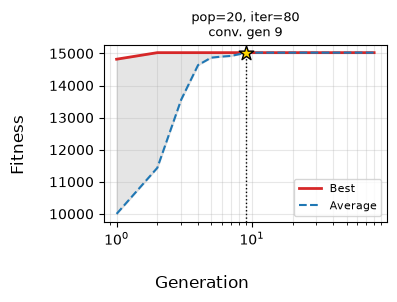

 Population  Iterations  Final avg.  Final best Conv. gen
         20          80    15,024.0    15,024.0         9

Gen | Average fitness | Best fitness
----|-----------------|-------------
  1 |       10,000.00 |    14,819.81
  2 |       11,435.83 |    15,024.04
  3 |       13,557.56 |    15,024.04
  4 |       14,637.27 |    15,024.04
  5 |       14,868.14 |    15,024.04
  6 |       14,901.50 |    15,024.04
  7 |       14,921.93 |    15,024.04
  8 |       14,972.98 |    15,024.04
  9 |       15,024.04 |    15,024.04
 10 |       15,024.04 |    15,024.04
 11 |       15,024.04 |    15,024.04
 12 |       15,024.04 |    15,024.04
 13 |       15,024.04 |    15,024.04
 14 |       15,024.04 |    15,024.04
 15 |       15,024.04 |    15,024.04
 16 |       15,024.04 |    15,024.04
 17 |       15,024.04 |    15,024.04
 18 |       15,024.04 |    15,024.04
 19 |       15,024.04 |    15,024.04
 20 |       15,024.04 |    15,024.04
 21 |       15,024.04 |    15,024.04
 22 |       15,024.04 |    15,02

In [19]:

df7 = sga_trial_and_results(20, 80)
display_dataframe(df7)

run = df7.iloc[0]
avg_hist, best_hist = np.array(run["avg_hist"]), np.array(run["best_hist"])
B, R = "\033[1m", "\033[0m"

print("\n" + B + "Gen | Average fitness | Best fitness" + R)
print("----|-----------------|-------------")
for g, (a, b) in enumerate(zip(avg_hist, best_hist), start=1):
    print("{:>3} | {:>15,.2f} | {:>12,.2f}".format(g, a, b))

print("\nAverage non-decreasing:", bool(np.all(np.diff(avg_hist) >= 0)))
print("Best non-decreasing:   ", bool(np.all(np.diff(best_hist) >= 0)))

final_pop = run["final_pop"]
best_ind = max(final_pop, key=lambda ind: fitness([ind])[0])
print("\nBest individual found: {} (x = {}, fitness = {:,.2f})".format(
    geno_to_str(best_ind), geno_to_pheno([best_ind])[0], fitness([best_ind])[0]))
print("Distinct genotypes in final population:", len({geno_to_str(i) for i in final_pop}))

##### **SGA Subtask: Results and Discussion**

We ran the SGA once with a population size of 20 for 80 generations ($P_C = 0.85$, $P_M = 1/6$). The table above lists the average and best fitness of the population at the start of every generation.

**Solution found.** The best individual is **011001 (x = 25)** with fitness **15,024.04**, which is the global maximum identified in the fitness subtask. The best fitness reached it in generation 2 (in generation 1 the best was 011000, x = 24, fitness 14,819.81). The average rose from 10,000.00 to 15,024.04 by generation 9 and stayed there. The final population contains a single distinct genotype: all 20 individuals are 011001.

**Is the fitness non-decreasing?** Yes, for both curves. The code check `np.all(np.diff(...) >= 0)` returns `True` for the average and for the best fitness.

**Why?** Both properties follow from our survivor selection, which is $(\mu + \lambda)$ truncation: parents and offspring are pooled and the $\mu$ fittest survive.

- *Best fitness:* the current best individual is in the pool, and no worse individual can displace it, so the best can never drop. The selection is elitist.
- *Average fitness:* sort the old population so that $f_{(1)} \ge f_{(2)} \ge \dots \ge f_{(\mu)}$. The pool still contains all of these individuals, so for every $k$ the $k$-th fittest member of the pool is at least $f_{(k)}$. The new population consists of the top $\mu$ of the pool, so each of its ranked members is at least as fit as the corresponding old one, and therefore its mean is at least the old mean. An offspring only enters the population by pushing out someone less fit.

**Is this what we expected?** Yes. Determinism alone would not guarantee it; what matters is that parents compete with their offspring. In a generational SGA, where offspring replace their parents, both curves can decrease. Fitness-proportional selection may never pick the best individual, and crossover or mutation can destroy it even if it is picked, so nothing protects the best solution or the population mean.

**Shape of the curves.** The average follows an S-shaped takeover curve. Once the optimum appears, copies of it spread because crossover between two copies of 011001 returns 011001, and an offspring escapes mutation with probability $(5/6)^6 \approx 0.33$. Survivor selection then keeps these copies and removes the weakest individuals. Most of the selection pressure comes from survivor selection, not from parent selection. Near the optimum, fitness-proportional selection barely distinguishes individuals: x = 24 has 98.6% of the fitness of x = 25, so it is selected almost as often.

**After convergence.** From generation 9 to 80 both curves are flat. Mutation still changes about two thirds of the offspring each generation ($1 - (5/6)^6 \approx 0.67$), but every mutant is worse than 011001 and is rejected by survivor selection. The population is frozen and exploration has stopped: the last 71 generations add nothing. This is harmless here because the population converged on the global optimum, but the same mechanism traps the search if it converges on a local optimum (see Subtask 8).

**Parameter choices.** $P_M = 1/6 = 1/L$ (with $L = 6$ bits) is the standard per-bit rate: on average one bit flips per offspring, which is enough to explore without destroying what the parents pass on. $P_C = 0.85$ makes recombination the main variation operator, while still letting 15% of the pairs pass through unchanged.

#### **Testing with varied parameters**

We perform four trials of four runs each, varying only `n_pop` and `n_iter`:

1. **Trial 1:** population doubles (4, 8, 16, 32), 100 iterations.
2. **Trial 2:** population fixed at 16, iterations increase (80, 120, 140, 160).
3. **Trial 3:** both increase together.
4. **Trial 4:** only 10 iterations, populations 12 to 48.

A run counts as *converged* in the first generation where the average is within 0.1% of the best (about 15 fitness units). The closest non-optimal individual (x = 24) is about 204 below the optimum, so for populations below 14 convergence means every individual has optimal fitness. For larger populations a few stray individuals are tolerated (one at 16 and 20, two at 32, three at 48). Convergence also only means that the average has caught up with the best; it does not mean the best is the global optimum.

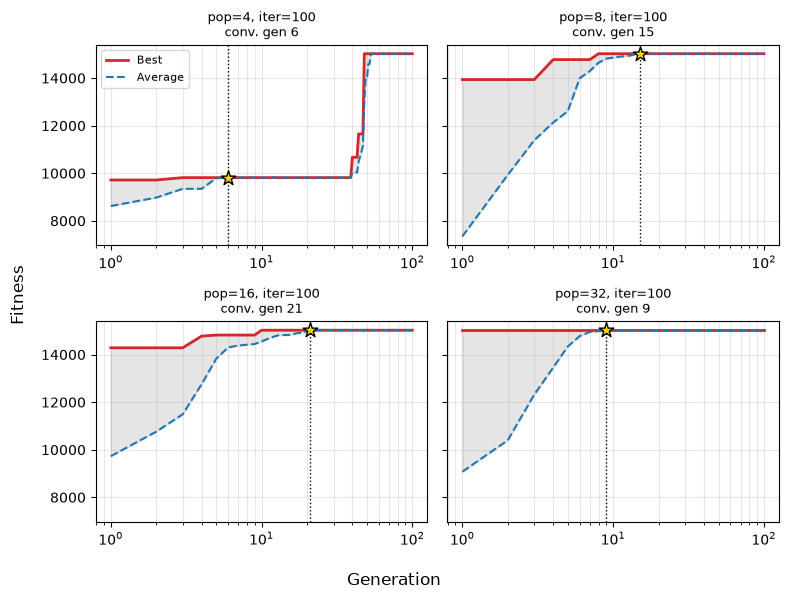

 Population  Iterations  Final avg.  Final best Conv. gen
          4         100    15,024.0    15,024.0         6
          8         100    15,024.0    15,024.0        15
         16         100    15,024.0    15,024.0        21
         32         100    15,024.0    15,024.0         9


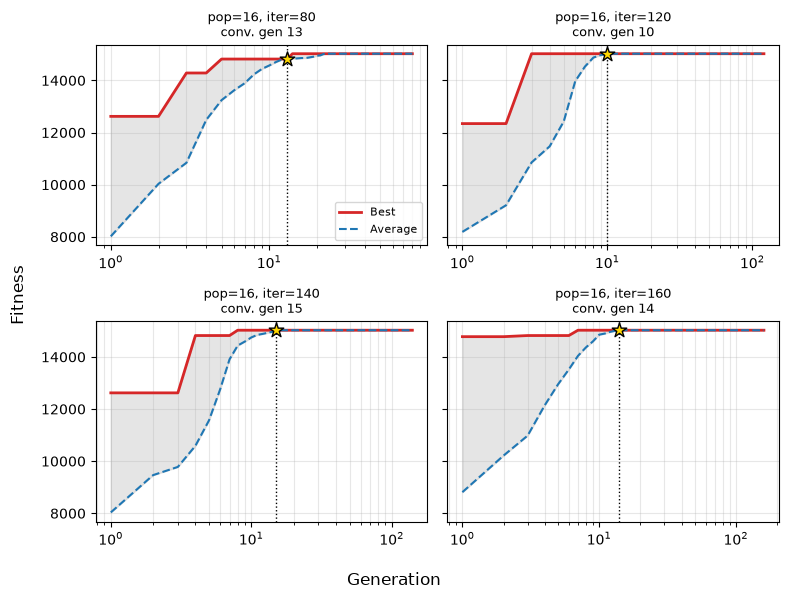

 Population  Iterations  Final avg.  Final best Conv. gen
         16          80    15,024.0    15,024.0        13
         16         120    15,024.0    15,024.0        10
         16         140    15,024.0    15,024.0        15
         16         160    15,024.0    15,024.0        14


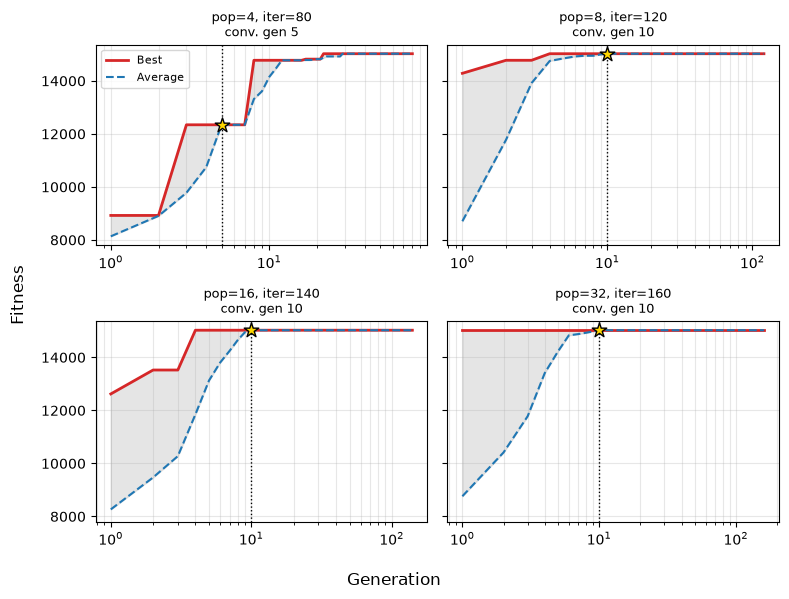

 Population  Iterations  Final avg.  Final best Conv. gen
          4          80    15,024.0    15,024.0         5
          8         120    15,024.0    15,024.0        10
         16         140    15,024.0    15,024.0        10
         32         160    15,024.0    15,024.0        10


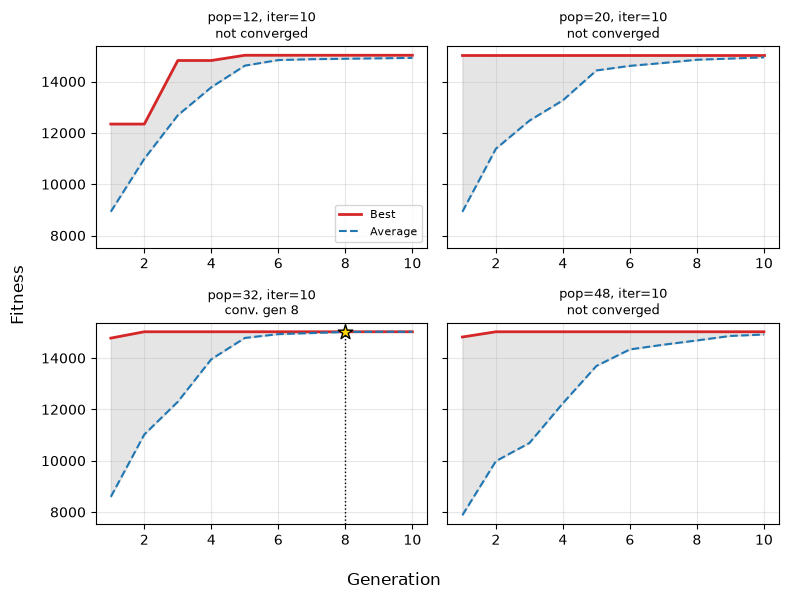

 Population  Iterations  Final avg.  Final best Conv. gen
         12          10    14,921.9    15,024.0         -
         20          10    14,942.4    15,024.0         -
         32          10    15,024.0    15,024.0         8
         48          10    14,916.3    15,024.0         -


In [20]:
t1_n_pop, t1_n_iter = [4, 8, 16, 32], 100
t2_n_pop, t2_n_iter  = 16, [80, 120, 140, 160]
t3_n_pop, t3_n_iter =  [4, 8, 16, 32], [80, 120, 140, 160]
t4_n_pop,  t4_n_iter = [12, 20, 32, 48], 10

trials = [ (t1_n_pop, t1_n_iter),
            (t2_n_pop, t2_n_iter),
            (t3_n_pop, t3_n_iter),
            (t4_n_pop,  t4_n_iter)
        ]

for n_pop, n_iter in trials:
    if isinstance(n_pop, int) or isinstance(n_iter, int):
        df: pd.DataFrame = sga_trial_and_results( n_pop, n_iter )
    else:
        df: pd.DataFrame = sga_trial_and_results( n_pop, n_iter, paired=True )
    display_dataframe( df )

In [21]:
def sga_replicates(pop_sizes, n_iter=100, n_reps=30, checkpoints=(1, 5, 10, 20, 50, 100), tolerance=0.001):
    """Runs the SGA n_reps times per population size and summarises the runs.
    n_iter only stops the loop, so generation t of a long run is distributed exactly like
    the final state of a run with n_iter = t. One long run per replicate therefore also
    answers the 'number of iterations' question."""
    f_opt = max(fitness(pheno_to_geno(range(64))))
    rows = []
    for n_pop in pop_sizes:
        params = {"n_pop": n_pop, "n_iter": n_iter, "c_prob": 0.85, "m_prob": 1/6, "n_bits": 6}
        found_gen, conv_gen, avg_at = [], [], {t: [] for t in checkpoints}
        for _ in range(n_reps):
            avg, best, _ = simple_genetic_algorithm(params)
            found_gen.append(next((g for g, b in enumerate(best, 1) if b >= f_opt - 1e-9), np.nan))
            c = find_convergence(avg, best, tolerance)
            conv_gen.append(np.nan if c is None else c)
            for t in checkpoints:
                avg_at[t].append(avg[t - 1])
        row = {"Population": n_pop,
               "Optimum in initial pop.": np.mean(np.array(found_gen) == 1),
               "Gen. optimum found": np.nanmean(found_gen),
               "Optimum found (any gen)": np.mean(~np.isnan(found_gen)),
               "Conv. gen (mean)": np.nanmean(conv_gen),
               "Conv. gen (sd)": np.nanstd(conv_gen)}
        for t in checkpoints:
            row["Avg @ gen {}".format(t)] = np.mean(avg_at[t])
        rows.append(row)
    return pd.DataFrame(rows)

rep_df = sga_replicates([4, 8, 12, 16, 20, 32, 48])
pd.set_option("display.width", 200)
print(rep_df.round(2).to_string(index=False))

 Population  Optimum in initial pop.  Gen. optimum found  Optimum found (any gen)  Conv. gen (mean)  Conv. gen (sd)  Avg @ gen 1  Avg @ gen 5  Avg @ gen 10  Avg @ gen 20  Avg @ gen 50  Avg @ gen 100
          4                     0.13               26.00                     0.93              8.80            3.50      8676.88     12656.25      13962.80      14242.32      14830.78       14974.78
          8                     0.00                8.47                     1.00             13.23            4.54      8403.47     13103.46      14713.28      14964.18      15024.04       15024.04
         12                     0.10                4.93                     1.00             11.27            2.37      8585.79     13737.18      14904.04      15023.48      15024.04       15024.04
         16                     0.23                4.17                     1.00             11.87            4.25      8538.74     13879.05      14871.00      15019.79      15024.04       15024.04
     

##### **Discussion of Results**

**The single-run trials.** The best fitness reached the global optimum, 15,024.04 (x = 25), in all 17 runs, including the Subtask 7 run. Every run with 80 or more iterations also ended with the whole population at the optimum. The only runs that ended below it are in Trial 4, with 10 iterations: the populations of 12, 20 and 48 ended with averages of 14,916 to 14,942. These runs were stopped part-way through the takeover, with some individuals still at neighbouring values such as x = 24.

The convergence generation, however, varies widely between runs, and much of that variation is noise. Trial 2 runs the *same* population size four times and converges at generations 13, 10, 15 and 14. The number of iterations cannot cause this difference, because `n_iter` only decides when the loop stops and convergence happened long before that. Population 16 converged at generation 21 in Trial 1 but at generation 10 in Trial 3. Population 32 converged at generation 9 with 100 iterations and at generation 8 with only 10. Single runs therefore cannot rank configurations, so we repeated the experiment with 30 runs per population size (table above). Since `n_iter` only truncates a run, the average fitness at generation $t$ of these 100-generation runs is exactly what a run with `n_iter` $= t$ would end with. The *Avg @ gen t* columns therefore answer the iterations question as well.

**Effect of population size.**

- *Finding the optimum.* A larger initial population is more likely to already contain the optimum, with probability $1 - (63/64)^N$: about 6% for 4 individuals, 22% for 16 and 53% for 48. The observed rates broadly follow this trend, although with only 30 runs per size they are noisy (population 8 never started with the optimum, which has a probability of about 2%). The mean generation in which the best fitness first reached the optimum falls from 8.5 (population 8) to 1.5 (population 48).
- *Average fitness.* At every checkpoint, larger populations have a higher average fitness. After 5 generations it is 13,103 for population 8 and 14,276 for population 48.
- *Convergence time* is roughly flat, between 10 and 13 generations, for populations of 8 and above, and drifts slightly downward. Two effects cancel out. A larger population finds the optimum sooner, but more individuals have to be replaced before the average catches up. With elitist truncation the number of copies of the optimum grows multiplicatively, so takeover time grows only slowly with population size. The looser tolerance at larger sizes also biases their convergence generation slightly downward.
- *Premature convergence in tiny populations.* Population 4 is the exception. Only 28 of the 30 runs found the optimum within 100 generations, and the runs that did needed 26 generations on average. In both failed runs the final population was four copies of **010111 (x = 23, fitness 14,285)**, a local optimum: every one-bit neighbour of it is less fit. Every fitter string is at least 3 bits away (x = 25 and x = 26 are 3 bits away, x = 24 is 4). With 4 identical individuals crossover cannot create anything new, and elitist survivor selection rejects every intermediate step because each one is worse. Escaping therefore needs several specific bits to flip in a single offspring, which happens with probability of only about 0.6% per offspring (about 2.3% per generation). These stuck runs still count as "converged" (mean convergence generation 8.8, the lowest in the table), which shows why fast convergence in a small population signals lost diversity rather than good performance.

**Effect of the number of iterations.** Iterations matter only until the population has converged. The average climbs steeply over the first 10 generations; by generation 20, populations of 20 or more are at the optimum in all 30 runs, and by generation 50 every population size from 8 upward is. Beyond that point, extra iterations change nothing: the population is frozen at 011001 and every mutant is rejected (see Subtask 7). This explains the results of the single-run trials. Trial 2 (80 to 160 iterations) shows no effect of iterations, while Trial 4 (10 iterations) stops close to the mean convergence generation, so most of its runs ended part-way through the takeover. The only configuration that still benefits from more iterations is population 4, where escaping from x = 23 is a rare event that needs time.

**Conclusion.** For this problem, a population of about 20 to 32 with 20 to 30 iterations reliably reaches the global optimum with a fully converged population. Smaller populations risk getting stuck on the local optimum at x = 23, and more iterations beyond convergence are wasted. Note that the search space contains only 64 genotypes: a population of 20 run for 20 generations already evaluates about 400 offspring, six times the size of the search space, so the GA is less efficient here than brute force. The trade-off between population size and iterations will matter far more on the knapsack problem, where the search space has $2^{1001}$ candidates.